# Logistic regression applied to coronary heart disease

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.linear_model import LogisticRegression

Data from Hosmer, D.W. & Lemeshow, S. (1989) Applied logistic regression. Wiley

Data are ages (in years) and indicator of significant damage in the coronary of 100 people

In [2]:
dat = pd.read_csv('heart_disease_vs_age.csv')

age = dat['age']
chd = dat['chd'].astype(int)

In [3]:
n = len(dat)
X = np.vstack([np.ones(n), dat['age']]).T
y = chd

## Logistic regression by hand

In [4]:
b = [0,0] # initial values

tolm   = 1e-6       # tolerance (minimum norm of the difference of the betas)
iterm  = 100        # maximum number of iterations
tolera = 1          # initialize tolera
itera  = 0          # initialize ittera
histo  = b          # initialize beta upgrade

while((tolera > tolm) and (itera < iterm)):
  p      = 1/(1+np.exp(-X @ b))
  W      = np.diag(p*(1-p))
  delta  = np.linalg.solve(X.T @ W @ X, X.T @ (y-p))
  b      = b+delta
  tolera = np.sqrt(sum(delta**2))
  histo  = np.vstack([histo, b])
  itera  = itera+1

histo

array([[ 0.        ,  0.        ],
       [-4.13935119,  0.0870007 ],
       [-5.15456916,  0.10781291],
       [-5.27679322,  0.11028762],
       [-5.27844413,  0.11032079],
       [-5.27844443,  0.11032079]])

In [5]:
# Create a grid of values to plot the function
n_grid = 300
x_grid = np.linspace(age.min(), age.max(), n_grid)
X_grid = np.vstack([np.ones(n_grid), x_grid]).T
p_grid = 1 / (1 + np.exp(-X_grid @ b))

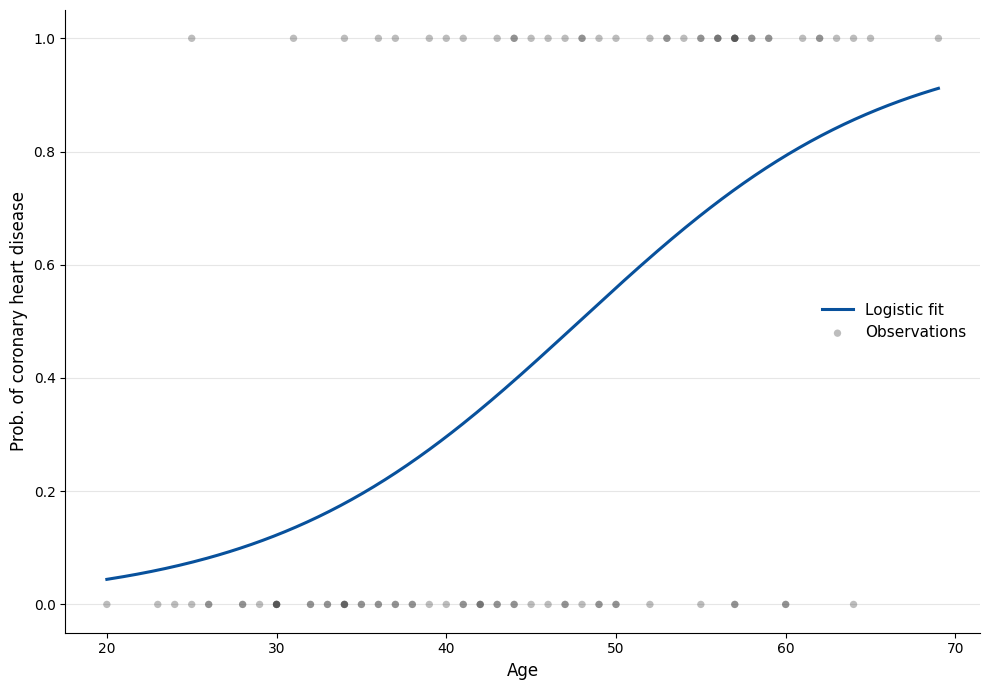

In [6]:
fig, ax = plt.subplots(figsize=(10, 7))

curve_color = '#08519c'   # deep blue for the fitted line
point_color = '#444444'   # neutral grey for observations

ax.plot(x_grid, p_grid, color=curve_color, linewidth=2.2, label='Logistic fit')
ax.scatter(age, chd, s=28, color=point_color, alpha=0.35, edgecolor='none', label='Observations')

ax.set_xlabel('Age', fontsize=12)
ax.set_ylabel('Prob. of coronary heart disease', fontsize=12)
ax.set_ylim(-0.05, 1.05)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e6', linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=11, loc='center right')

plt.tight_layout()

## Using LogisticRegression

In [7]:
model = LogisticRegression(penalty=None)
model.fit(np.array(age)[:,None], y)

# Write the coefficients in an array
coef = np.ravel(model.coef_)
intercept = np.ravel(model.intercept_)[0]
b = np.array([intercept, coef[0]])

b

array([-5.27848182,  0.11032174])

In [8]:
# model.predict_proba calculate the prob. of y=1, and y=0.
p_grid = model.predict_proba(np.array(x_grid)[:,None]).T[1]

### Adding confidence intervals to the logistic curve

In [9]:
alpha = 0.05

# Calculate variance of eta, and confidence intervals for p
var_eta = np.diag(X_grid @ np.linalg.solve(X.T @ W @ X, X_grid.T))
sd_eta = np.sqrt(var_eta)
upp = p_grid / (p_grid + (1-p_grid) * np.exp(norm.ppf(alpha/2)*sd_eta))
low = p_grid / (p_grid + (1-p_grid) * np.exp(-norm.ppf(alpha/2)*sd_eta))

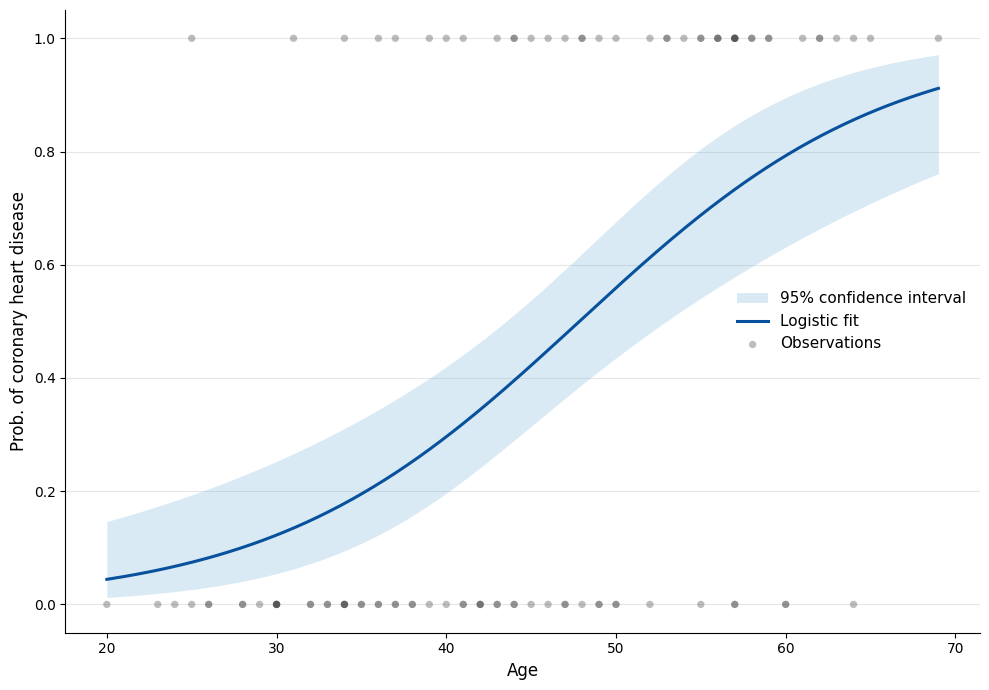

In [10]:
fig, ax = plt.subplots(figsize=(10, 7))

curve_color = '#08519c'   # deep blue for the fitted line
band_color  = '#6baed6'   # lighter blue for the CI band
point_color = '#444444'   # neutral grey for observations

ci_label = f'{(1 - alpha) * 100:.0f}% confidence interval'

ax.fill_between(x_grid, low, upp, color=band_color, alpha=0.25, linewidth=0, label=ci_label)
ax.plot(x_grid, p_grid, color=curve_color, linewidth=2.2, label='Logistic fit')
ax.scatter(age, chd, s=28, color=point_color, alpha=0.35, edgecolor='none', label='Observations')

ax.set_xlabel('Age', fontsize=12)
ax.set_ylabel('Prob. of coronary heart disease', fontsize=12)
ax.set_ylim(-0.05, 1.05)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e6', linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=11, loc='center right')

plt.tight_layout()